# Linear-regression fitness score and model grouping

This notebook learns one shared five-metric scoring equation, predicts a continuous **fitness score**, and groups the seven candidate models into **more fit** and **less fit**.

The primary experiment uses nested leave-one-dataset-out validation. Ten sampling repetitions are averaged into 49 independent dataset-model rows. Repetitions are analysed separately at the end for decision uncertainty.



In [1]:
# 1. Imports, files, and settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, mean_squared_error, precision_score, recall_score)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "Standardizing":
    PROJECT_ROOT = PROJECT_ROOT.parent
METRIC_FILE = PROJECT_ROOT / "Standardizing/results/rank_prediction_uncertainty10_label_first/all_datasets_model_metrics_10runs.csv"
F1_FILE = PROJECT_ROOT / "Standardizing/results/finetuning_8epochs_5fold/model_summary.csv"
OUTPUT_DIR = PROJECT_ROOT / "Standardizing/results/linear_regression_fitness"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURES = ["same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta", "chi2_distance"]
FEATURE_LABELS = {"same_mean":"Same Mean", "diff_mean":"Different Mean",
                  "same_abs_eta":"Same |eta|", "diff_abs_eta":"Different |eta|",
                  "chi2_distance":"Chi-square Distance"}
Z_FEATURES = [f"z_{x}" for x in FEATURES]
TARGET, Z_TARGET = "macro_f1_mean", "z_macro_f1_mean"
ALPHAS = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
DATASET_ORDER = ["Financial", "EnvData", "ACGNews", "ECtHR", "Ohsumed", "Rheology", "arXiv"]
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
print("Output directory:", OUTPUT_DIR)



Output directory: /home/amyliu/Desktop/GR/Standardizing/results/linear_regression_fitness


## Load, audit, and build the 49-row regression table

For each dataset-model pair, the five metrics are averaged across ten samples. Metrics and Macro-F1 are z-standardized within each dataset so the equation predicts relative model fitness rather than task difficulty.



In [2]:
# 2. Load completed results and audit completeness
metric_runs_df = pd.read_csv(METRIC_FILE)
f1_df = pd.read_csv(F1_FILE)
required_metrics = {"dataset", "model", "repetition", *FEATURES}
required_f1 = {"dataset", "model", TARGET}
if required_metrics - set(metric_runs_df):
    raise ValueError(f"Missing metric columns: {sorted(required_metrics-set(metric_runs_df))}")
if required_f1 - set(f1_df):
    raise ValueError(f"Missing F1 columns: {sorted(required_f1-set(f1_df))}")
audit = metric_runs_df.groupby("dataset").agg(
    rows=("model", "size"), models=("model", "nunique"), repetitions=("repetition", "nunique")
).reindex(DATASET_ORDER)
if not audit["models"].eq(7).all():
    raise ValueError(f"Expected 7 models per dataset:\n{audit}")
if not audit["repetitions"].eq(10).all():
    raise ValueError(f"Expected 10 repetitions per dataset:\n{audit}")
if metric_runs_df.duplicated(["dataset", "model", "repetition"]).any():
    raise ValueError("Duplicate metric rows")
if "complete" in f1_df.columns:
    f1_df = f1_df[f1_df["complete"].astype(bool)].copy()
if f1_df.duplicated(["dataset", "model"]).any():
    raise ValueError("Duplicate F1 rows")

metric_means_df = metric_runs_df.groupby(["dataset", "model"], as_index=False)[FEATURES].mean()
regression_df = metric_means_df.merge(f1_df[["dataset", "model", TARGET]],
    on=["dataset", "model"], how="left", validate="one_to_one")
if regression_df[TARGET].isna().any():
    raise ValueError("Some dataset-model rows have no Macro-F1")
if len(regression_df) != 49:
    raise ValueError(f"Expected 49 rows, found {len(regression_df)}")

def add_within_dataset_zscores(frame, columns):
    result = frame.copy()
    for column in columns:
        grouped = result.groupby("dataset")[column]
        mu, sd = grouped.transform("mean"), grouped.transform("std")
        if sd.isna().any() or sd.le(0).any():
            raise ValueError(f"Cannot standardize {column}")
        result[f"z_{column}"] = (result[column] - mu) / sd
    return result

regression_df = add_within_dataset_zscores(regression_df, FEATURES + [TARGET])
regression_df.to_csv(OUTPUT_DIR / "regression_input_49rows.csv", index=False)
print("Independent regression observations:", len(regression_df))
display(audit)
display(regression_df.head(10))



Independent regression observations: 49


,rows,models,repetitions
dataset,,,
Financial,70,7,10
EnvData,70,7,10
ACGNews,70,7,10
ECtHR,70,7,10
Ohsumed,70,7,10
Rheology,70,7,10
arXiv,70,7,10


,dataset,model,same_mean,diff_mean,same_abs_eta,diff_abs_eta,chi2_distance,macro_f1_mean,z_same_mean,z_diff_mean,z_same_abs_eta,z_diff_abs_eta,z_chi2_distance,z_macro_f1_mean
0,ACGNews,Lianglab/PharmBERT-uncased,0.766299,0.739224,0.248034,0.231163,0.061517,0.943526,-0.834797,-0.761994,-0.211780,-0.237039,0.000504,0.782917
1,ACGNews,ahmedrachid/FinancialBERT,0.819340,0.796348,0.320468,0.266787,0.057649,0.928288,-0.084488,-0.090774,0.497688,0.198755,-0.107782,-1.610680
2,ACGNews,allenai/scibert_scivocab_uncased,0.834709,0.818371,0.283389,0.264428,0.056877,0.940961,0.132931,0.167994,0.134516,0.169898,-0.129392,0.379880
3,ACGNews,google-bert/bert-base-uncased,0.702961,0.652442,0.067801,0.104537,0.131271,0.944763,-1.730788,-1.781702,-1.977080,-1.786115,1.953275,0.977175
4,ACGNews,nlpaueb/legal-bert-base-uncased,0.896337,0.884760,0.262024,0.256951,0.052150,0.939663,1.004722,0.948084,-0.074745,0.078428,-0.261730,0.176043
5,ACGNews,recobo/agriculture-bert-uncased,0.860782,0.844854,0.304821,0.245665,0.061143,0.941650,0.501749,0.479177,0.344429,-0.059632,-0.009969,0.488116
6,ACGNews,recobo/chemical-bert-uncased,0.896758,0.892516,0.401052,0.384247,0.009886,0.930944,1.010672,1.039215,1.286972,1.635705,-1.444907,-1.193450
7,ECtHR,Lianglab/PharmBERT-uncased,0.925503,0.914195,0.499224,0.404182,0.062776,0.188051,-0.132505,-0.125218,-0.091486,-0.379325,0.276602,-0.319015
8,ECtHR,ahmedrachid/FinancialBERT,0.928810,0.916358,0.470529,0.446085,0.056071,0.179929,0.045184,-0.032542,-0.489347,0.146758,0.048492,-0.738470
9,ECtHR,allenai/scibert_scivocab_uncased,0.914851,0.902160,0.476295,0.423822,0.048990,0.207115,-0.704875,-0.640946,-0.409398,-0.132744,-0.192389,0.665638


## Regression, nested alpha selection, and grouping helpers

`alpha=0` is ordinary linear regression. Positive values use Ridge. Alpha is selected only inside the six outer-training datasets. The one-dimensional cluster with the higher centre is labelled more fit.



In [3]:
# 3. Reusable functions
def fit_regressor(alpha, X, y):
    model = LinearRegression() if np.isclose(alpha, 0) else Ridge(alpha=float(alpha))
    return model.fit(X, y)

def safe_spearman(y, prediction):
    return np.nan if np.unique(prediction).size < 2 else float(spearmanr(y, prediction).statistic)

def safe_pearson(y, prediction):
    return np.nan if np.unique(prediction).size < 2 else float(pearsonr(y, prediction).statistic)

def select_alpha_nested(training_df):
    rows = []
    for alpha in ALPHAS:
        for validation_dataset in sorted(training_df["dataset"].unique()):
            inner_train = training_df[training_df["dataset"] != validation_dataset]
            validation = training_df[training_df["dataset"] == validation_dataset]
            model = fit_regressor(alpha, inner_train[Z_FEATURES], inner_train[Z_TARGET])
            prediction = model.predict(validation[Z_FEATURES])
            truth = validation[Z_TARGET].to_numpy()
            rows.append({"alpha":float(alpha), "validation_dataset":validation_dataset,
                         "spearman":safe_spearman(truth, prediction),
                         "rmse":float(np.sqrt(mean_squared_error(truth, prediction)))})
    folds = pd.DataFrame(rows)
    summary = folds.groupby("alpha", as_index=False).agg(
        mean_spearman=("spearman", "mean"), mean_rmse=("rmse", "mean")
    ).sort_values(["mean_spearman", "mean_rmse", "alpha"], ascending=[False, True, True]).reset_index(drop=True)
    return float(summary.iloc[0]["alpha"]), folds, summary

def two_groups(values):
    values = np.asarray(values, dtype=float).reshape(-1, 1)
    if np.unique(values).size < 2:
        raise ValueError("Grouping requires at least two distinct values")
    clustering = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit(values)
    more_fit_cluster = int(np.argmax(clustering.cluster_centers_.ravel()))
    return (clustering.labels_ == more_fit_cluster).astype(int), clustering.cluster_centers_.ravel()

def evaluate_fold(test_df, scores):
    truth, actual_f1 = test_df[Z_TARGET].to_numpy(), test_df[TARGET].to_numpy()
    predicted_group, _ = two_groups(scores)
    actual_group, _ = two_groups(actual_f1)
    predicted_best, actual_best = int(np.argmax(scores)), int(np.argmax(actual_f1))
    metrics = {
        "spearman":safe_spearman(truth, scores), "pearson":safe_pearson(truth, scores),
        "rmse":float(np.sqrt(mean_squared_error(truth, scores))),
        "mae":float(mean_absolute_error(truth, scores)),
        "more_fit_precision":float(precision_score(actual_group, predicted_group, zero_division=0)),
        "more_fit_recall":float(recall_score(actual_group, predicted_group, zero_division=0)),
        "more_fit_f1":float(f1_score(actual_group, predicted_group, zero_division=0)),
        "balanced_accuracy":float(balanced_accuracy_score(actual_group, predicted_group)),
        "adjusted_rand_index":float(adjusted_rand_score(actual_group, predicted_group)),
        "top1_correct":int(predicted_best == actual_best),
        "f1_regret":float(actual_f1.max() - actual_f1[predicted_best]),
        "predicted_more_fit_n":int(predicted_group.sum()), "actual_more_fit_n":int(actual_group.sum())}
    return metrics, predicted_group, actual_group



## Primary experiment: nested leave-one-dataset-out prediction

Every test dataset is excluded from both coefficient fitting and alpha selection.



In [4]:
# 4. Seven outer folds
outer_rows, prediction_frames, coefficient_rows, inner_frames, alpha_frames = [], [], [], [], []
for held_out in DATASET_ORDER:
    train = regression_df[regression_df["dataset"] != held_out]
    test = regression_df[regression_df["dataset"] == held_out].copy()
    alpha, inner_folds, alpha_summary = select_alpha_nested(train)
    inner_folds["held_out_dataset"], alpha_summary["held_out_dataset"] = held_out, held_out
    inner_frames.append(inner_folds); alpha_frames.append(alpha_summary)
    model = fit_regressor(alpha, train[Z_FEATURES], train[Z_TARGET])
    scores = model.predict(test[Z_FEATURES])
    evaluation, predicted_group, actual_group = evaluate_fold(test, scores)
    evaluation.update({"held_out_dataset":held_out, "selected_alpha":alpha, "intercept":float(model.intercept_)})
    outer_rows.append(evaluation)
    for feature, coefficient in zip(FEATURES, model.coef_):
        coefficient_rows.append({"held_out_dataset":held_out, "selected_alpha":alpha,
                                 "feature":feature, "coefficient":float(coefficient)})
    test["fitness_score"] = scores
    test["predicted_group"] = np.where(predicted_group == 1, "more_fit", "less_fit")
    test["actual_group"] = np.where(actual_group == 1, "more_fit", "less_fit")
    test["selected_alpha"] = alpha
    test["predicted_rank"] = test["fitness_score"].rank(ascending=False, method="min").astype(int)
    test["actual_rank"] = test[TARGET].rank(ascending=False, method="min").astype(int)
    prediction_frames.append(test)
    print(f"{held_out}: alpha={alpha}, Spearman={evaluation['spearman']:.3f}, group F1={evaluation['more_fit_f1']:.3f}")

outer_metrics_df = pd.DataFrame(outer_rows)
fitness_predictions_df = pd.concat(prediction_frames, ignore_index=True)
coefficients_df = pd.DataFrame(coefficient_rows)
inner_search_df = pd.concat(inner_frames, ignore_index=True)
alpha_summary_df = pd.concat(alpha_frames, ignore_index=True)
outer_metrics_df.to_csv(OUTPUT_DIR / "outer_dataset_metrics.csv", index=False)
fitness_predictions_df.to_csv(OUTPUT_DIR / "fitness_predictions.csv", index=False)
coefficients_df.to_csv(OUTPUT_DIR / "outer_coefficients.csv", index=False)
inner_search_df.to_csv(OUTPUT_DIR / "inner_alpha_search_folds.csv", index=False)
alpha_summary_df.to_csv(OUTPUT_DIR / "inner_alpha_search_summary.csv", index=False)
display(outer_metrics_df.round(4))



Financial: alpha=0.01, Spearman=0.429, group F1=1.000
EnvData: alpha=0.0, Spearman=0.750, group F1=0.667
ACGNews: alpha=0.0, Spearman=0.786, group F1=0.909
ECtHR: alpha=0.001, Spearman=0.821, group F1=0.750
Ohsumed: alpha=0.001, Spearman=0.929, group F1=0.500
Rheology: alpha=0.001, Spearman=0.714, group F1=0.909
arXiv: alpha=0.001, Spearman=0.643, group F1=0.500


,spearman,pearson,rmse,mae,more_fit_precision,more_fit_recall,more_fit_f1,balanced_accuracy,adjusted_rand_index,top1_correct,f1_regret,predicted_more_fit_n,actual_more_fit_n,held_out_dataset,selected_alpha,intercept
0,0.4286,0.8272,0.5677,0.4145,1.0000,1.0000,1.0000,1.0000,1.0000,1,0.0000,6,6,Financial,0.010,-0.0
1,0.7500,0.6868,0.6765,0.6292,1.0000,0.5000,0.6667,0.7500,-0.0769,0,0.0080,3,6,EnvData,0.000,-0.0
2,0.7857,0.6475,0.7193,0.5441,0.8333,1.0000,0.9091,0.7500,0.4167,1,0.0000,6,5,ACGNews,0.000,-0.0
3,0.8214,0.8346,0.5100,0.4039,0.6000,1.0000,0.7500,0.7500,0.0541,1,0.0000,5,3,ECtHR,0.001,-0.0
4,0.9286,0.8309,0.5274,0.4074,1.0000,0.3333,0.5000,0.6667,0.1026,1,0.0000,1,3,Ohsumed,0.001,-0.0
5,0.7143,0.8425,0.4996,0.4830,1.0000,0.8333,0.9091,0.9167,0.4167,0,0.0117,5,6,Rheology,0.001,-0.0
6,0.6429,0.6017,0.7852,0.6471,0.6667,0.4000,0.5000,0.4500,-0.1351,0,0.0065,3,5,arXiv,0.001,-0.0


## Performance, equations, and coefficient stability



In [5]:
# 5. Summaries
overall_summary_df = pd.DataFrame({"measure":["Mean Spearman", "Mean Pearson", "Mean RMSE", "Mean MAE",
    "Mean more-fit F1", "Mean balanced accuracy", "Mean adjusted Rand index", "Top-1 accuracy", "Mean F1 regret"],
    "value":[outer_metrics_df["spearman"].mean(), outer_metrics_df["pearson"].mean(), outer_metrics_df["rmse"].mean(),
    outer_metrics_df["mae"].mean(), outer_metrics_df["more_fit_f1"].mean(), outer_metrics_df["balanced_accuracy"].mean(),
    outer_metrics_df["adjusted_rand_index"].mean(), outer_metrics_df["top1_correct"].mean(), outer_metrics_df["f1_regret"].mean()]})
coefficient_summary_df = coefficients_df.groupby("feature", as_index=False).agg(
    coefficient_mean=("coefficient", "mean"), coefficient_sd=("coefficient", "std"),
    coefficient_min=("coefficient", "min"), coefficient_max=("coefficient", "max"),
    positive_folds=("coefficient", lambda x:int((x > 0).sum())),
    negative_folds=("coefficient", lambda x:int((x < 0).sum())))
overall_summary_df.to_csv(OUTPUT_DIR / "overall_summary.csv", index=False)
coefficient_summary_df.to_csv(OUTPUT_DIR / "coefficient_stability.csv", index=False)
display(overall_summary_df.round(4)); display(coefficient_summary_df.round(4))
for held_out in DATASET_ORDER:
    info = outer_metrics_df[outer_metrics_df["held_out_dataset"] == held_out].iloc[0]
    coefs = coefficients_df[coefficients_df["held_out_dataset"] == held_out].set_index("feature")["coefficient"]
    terms = " ".join(f"({coefs[f]:+.4f} × z_{f})" for f in FEATURES)
    print(f"Hold out {held_out}: score = {info['intercept']:+.4f} {terms}")



,measure,value
0,Mean Spearman,0.7245
1,Mean Pearson,0.7530
2,Mean RMSE,0.6122
3,Mean MAE,0.5042
4,Mean more-fit F1,0.7478
5,Mean balanced accuracy,0.7548
6,Mean adjusted Rand index,0.2540
7,Top-1 accuracy,0.5714
8,Mean F1 regret,0.0038


,feature,coefficient_mean,coefficient_sd,coefficient_min,coefficient_max,positive_folds,negative_folds
0,chi2_distance,0.1011,0.0511,0.0603,0.2039,7,0
1,diff_abs_eta,-1.2343,0.0777,-1.3183,-1.1141,0,7
2,diff_mean,1.8177,0.1337,1.6683,1.9947,7,0
3,same_abs_eta,0.5630,0.0809,0.4555,0.6738,7,0
4,same_mean,-1.8141,0.1219,-2.0331,-1.7065,0,7


Hold out Financial: score = -0.0000 (-2.0331 × z_same_mean) (+1.9947 × z_diff_mean) (+0.5765 × z_same_abs_eta) (-1.1141 × z_diff_abs_eta) (+0.2039 × z_chi2_distance)
Hold out EnvData: score = -0.0000 (-1.7065 × z_same_mean) (+1.6683 × z_diff_mean) (+0.5776 × z_same_abs_eta) (-1.2582 × z_diff_abs_eta) (+0.0603 × z_chi2_distance)
Hold out ACGNews: score = -0.0000 (-1.7175 × z_same_mean) (+1.6789 × z_diff_mean) (+0.6738 × z_same_abs_eta) (-1.3183 × z_diff_abs_eta) (+0.1090 × z_chi2_distance)
Hold out ECtHR: score = -0.0000 (-1.9183 × z_same_mean) (+1.9211 × z_diff_mean) (+0.5688 × z_same_abs_eta) (-1.2278 × z_diff_abs_eta) (+0.1234 × z_chi2_distance)
Hold out Ohsumed: score = -0.0000 (-1.7308 × z_same_mean) (+1.7694 × z_diff_mean) (+0.6292 × z_same_abs_eta) (-1.3083 × z_diff_abs_eta) (+0.0708 × z_chi2_distance)
Hold out Rheology: score = -0.0000 (-1.7662 × z_same_mean) (+1.7462 × z_diff_mean) (+0.4555 × z_same_abs_eta) (-1.1471 × z_diff_abs_eta) (+0.0654 × z_chi2_distance)
Hold out arXiv:

## Visualize held-out fitness scores and coefficients



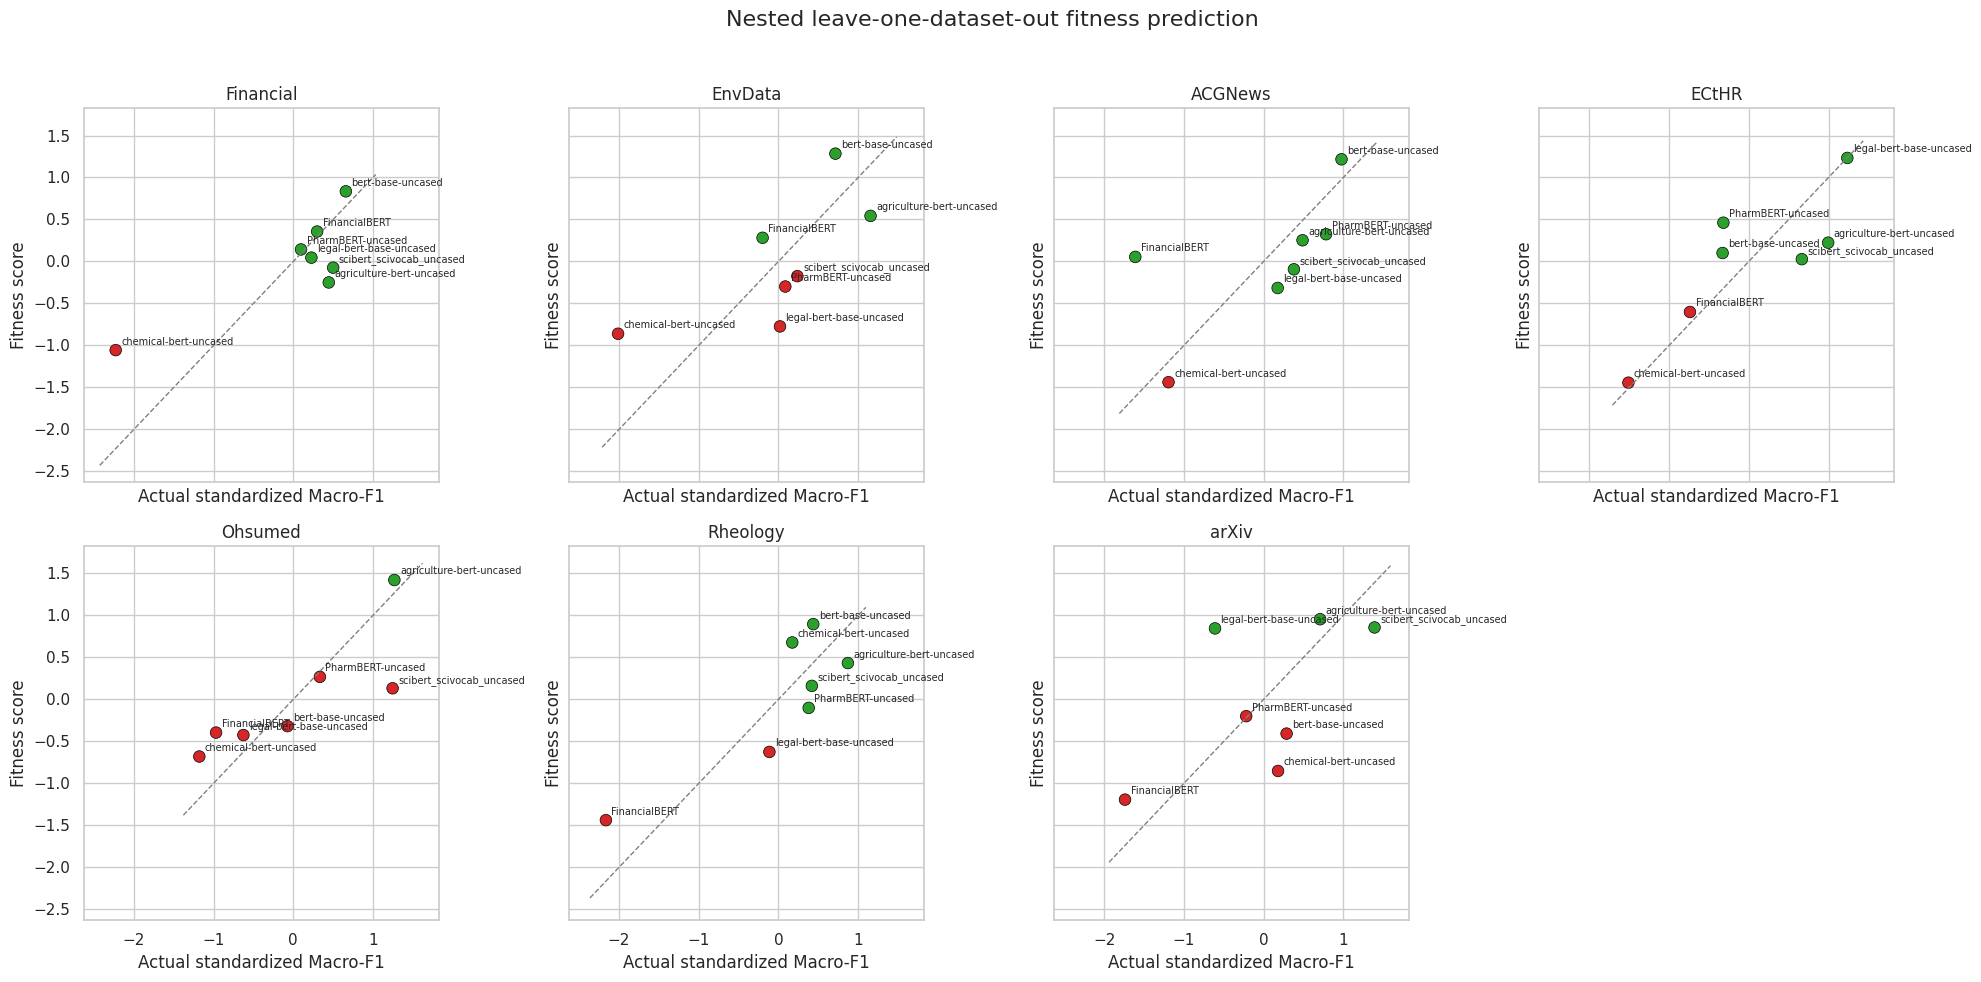

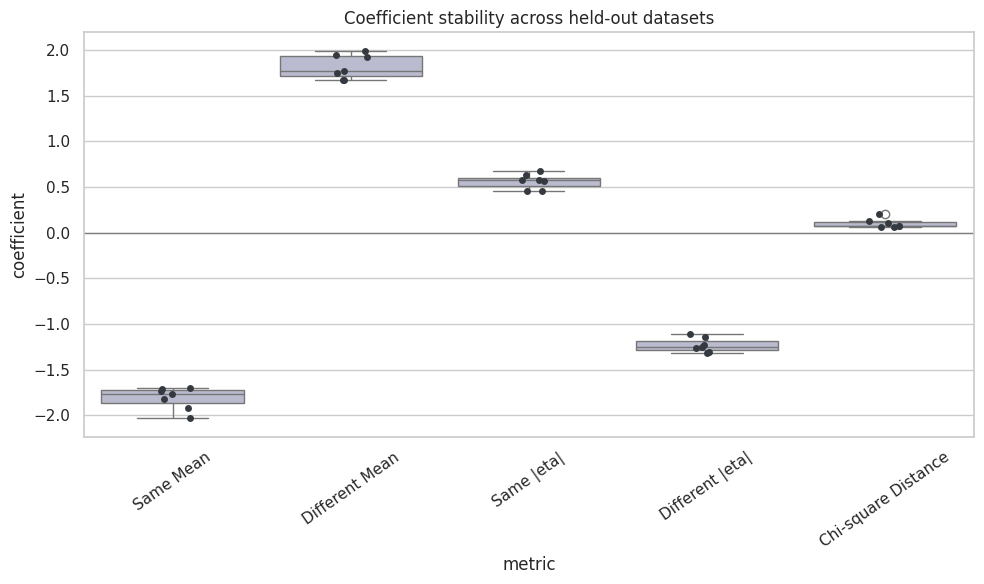

In [6]:
# 6. Figures
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True)
for axis, dataset in zip(axes.flat, DATASET_ORDER):
    subset = fitness_predictions_df[fitness_predictions_df["dataset"] == dataset]
    colours = subset["predicted_group"].map({"more_fit":"#2ca02c", "less_fit":"#d62728"})
    axis.scatter(subset[Z_TARGET], subset["fitness_score"], c=colours, s=70, edgecolor="black", linewidth=.5)
    for _, row in subset.iterrows():
        axis.annotate(row["model"].split("/")[-1], (row[Z_TARGET], row["fitness_score"]),
                      xytext=(4,4), textcoords="offset points", fontsize=7)
    low = min(subset[Z_TARGET].min(), subset["fitness_score"].min()) - .2
    high = max(subset[Z_TARGET].max(), subset["fitness_score"].max()) + .2
    axis.plot([low, high], [low, high], "--", color="gray", linewidth=1)
    axis.set_title(dataset); axis.set_xlabel("Actual standardized Macro-F1"); axis.set_ylabel("Fitness score")
axes.flat[-1].axis("off")
fig.suptitle("Nested leave-one-dataset-out fitness prediction", fontsize=16)
fig.tight_layout(rect=[0,0,1,.96]); fig.savefig(OUTPUT_DIR / "fitness_prediction_by_dataset.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

coefficient_plot = coefficients_df.copy(); coefficient_plot["metric"] = coefficient_plot["feature"].map(FEATURE_LABELS)
fig, axis = plt.subplots(figsize=(10,6))
sns.boxplot(data=coefficient_plot, x="metric", y="coefficient", color="#b7b8d2", ax=axis)
sns.stripplot(data=coefficient_plot, x="metric", y="coefficient", color="#343a40", size=5, ax=axis)
axis.axhline(0, color="gray", linewidth=1); axis.set_title("Coefficient stability across held-out datasets")
axis.tick_params(axis="x", rotation=35); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "coefficient_stability.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)



## Sampling uncertainty of fitness scores and groups

Outer-fold equations stay fixed. Each of ten metric repetitions is passed through its held-out equation. The result reports fitness SD and more-fit assignment counts.



In [7]:
# 7. Propagate ten document samples to final decisions
repetition_frames = []
for held_out in DATASET_ORDER:
    train = regression_df[regression_df["dataset"] != held_out]
    alpha = float(outer_metrics_df.loc[outer_metrics_df["held_out_dataset"] == held_out, "selected_alpha"].iloc[0])
    model = fit_regressor(alpha, train[Z_FEATURES], train[Z_TARGET])
    reference = regression_df[regression_df["dataset"] == held_out][["model", TARGET, Z_TARGET]]
    held_runs = metric_runs_df[metric_runs_df["dataset"] == held_out]
    for repetition in sorted(held_runs["repetition"].unique()):
        rep = held_runs[held_runs["repetition"] == repetition][["dataset", "model", "repetition", *FEATURES]].copy()
        rep = add_within_dataset_zscores(rep, FEATURES).merge(reference, on="model", validate="one_to_one")
        scores = model.predict(rep[Z_FEATURES]); groups, _ = two_groups(scores)
        rep["fitness_score"] = scores; rep["predicted_group"] = np.where(groups == 1, "more_fit", "less_fit")
        repetition_frames.append(rep)
fitness_repetitions_df = pd.concat(repetition_frames, ignore_index=True)
fitness_uncertainty_df = fitness_repetitions_df.groupby(["dataset", "model"], as_index=False).agg(
    actual_macro_f1=(TARGET, "first"), fitness_mean=("fitness_score", "mean"), fitness_sd=("fitness_score", "std"),
    fitness_min=("fitness_score", "min"), fitness_max=("fitness_score", "max"),
    more_fit_rounds=("predicted_group", lambda x:int((x == "more_fit").sum())))
fitness_uncertainty_df["less_fit_rounds"] = 10 - fitness_uncertainty_df["more_fit_rounds"]
fitness_repetitions_df.to_csv(OUTPUT_DIR / "fitness_predictions_per_repetition.csv", index=False)
fitness_uncertainty_df.to_csv(OUTPUT_DIR / "fitness_uncertainty_summary.csv", index=False)
display(fitness_uncertainty_df.sort_values(["dataset", "fitness_mean"], ascending=[True,False]).round(4))



,dataset,model,actual_macro_f1,fitness_mean,fitness_sd,fitness_min,fitness_max,more_fit_rounds,less_fit_rounds
3,ACGNews,google-bert/bert-base-uncased,0.9448,1.0785,0.2761,0.7108,1.5523,10,0
0,ACGNews,Lianglab/PharmBERT-uncased,0.9435,0.2874,0.4423,-0.2097,0.9683,6,4
5,ACGNews,recobo/agriculture-bert-uncased,0.9416,0.2213,0.4452,-0.6618,0.7309,5,5
1,ACGNews,ahmedrachid/FinancialBERT,0.9283,0.1202,0.5683,-0.6148,1.0133,4,6
2,ACGNews,allenai/scibert_scivocab_uncased,0.9410,-0.1043,0.6109,-0.9697,1.2597,3,7
4,ACGNews,nlpaueb/legal-bert-base-uncased,0.9397,-0.2819,0.5047,-1.2703,0.3323,3,7
6,ACGNews,recobo/chemical-bert-uncased,0.9309,-1.3212,0.2812,-1.7027,-0.9058,0,10
11,ECtHR,nlpaueb/legal-bert-base-uncased,0.2182,1.0074,1.0890,-0.5375,2.3426,6,4
7,ECtHR,Lianglab/PharmBERT-uncased,0.1881,0.4045,1.1851,-1.5746,2.3923,8,2
12,ECtHR,recobo/agriculture-bert-uncased,0.2135,0.0186,0.5314,-1.1055,0.8739,4,6


## Final future-use equation

After honest evaluation, fit one equation using all seven datasets. Its training fit is not test performance.



In [8]:
# 8. Final deployable equation
final_alpha, final_folds, final_search = select_alpha_nested(regression_df)
final_model = fit_regressor(final_alpha, regression_df[Z_FEATURES], regression_df[Z_TARGET])
final_equation_df = pd.DataFrame({"feature":FEATURES, "coefficient":final_model.coef_})
final_equation_df["intercept"] = float(final_model.intercept_); final_equation_df["selected_alpha"] = final_alpha
final_search.to_csv(OUTPUT_DIR / "final_alpha_selection.csv", index=False)
final_equation_df.to_csv(OUTPUT_DIR / "final_fitness_equation.csv", index=False)
terms = " ".join(f"({coefficient:+.6f} × z_{feature})" for feature, coefficient in zip(FEATURES, final_model.coef_))
print("Selected final alpha:", final_alpha)
print(f"Fitness score = {float(final_model.intercept_):+.6f} {terms}")
display(final_equation_df.round(6))


Selected final alpha: 0.1
Fitness score = -0.000000 (-1.041283 × z_same_mean) (+1.029347 × z_diff_mean) (+0.540409 × z_same_abs_eta) (-1.201022 × z_diff_abs_eta) (+0.079142 × z_chi2_distance)


,feature,coefficient,intercept,selected_alpha
0,same_mean,-1.041283,-0.0,0.1
1,diff_mean,1.029347,-0.0,0.1
2,same_abs_eta,0.540409,-0.0,0.1
3,diff_abs_eta,-1.201022,-0.0,0.1
4,chi2_distance,0.079142,-0.0,0.1


## Predicted rank versus actual Macro-F1 rank

The actual rank is determined by Macro-F1 within each dataset; the predicted rank is determined by the held-out fitness score. Rank error is predicted rank minus actual rank, so zero indicates an exact match.

In [9]:
# 9. Compare held-out predicted ranks with actual Macro-F1 ranks
rank_comparison_df = (
    fitness_predictions_df[[
        "dataset",
        "model",
        TARGET,
        "fitness_score",
        "actual_rank",
        "predicted_rank",
        "actual_group",
        "predicted_group",
    ]]
    .copy()
)

rank_comparison_df["rank_error"] = (
    rank_comparison_df["predicted_rank"]
    - rank_comparison_df["actual_rank"]
)
rank_comparison_df["absolute_rank_error"] = (
    rank_comparison_df["rank_error"].abs()
)
rank_comparison_df["exact_rank_match"] = (
    rank_comparison_df["absolute_rank_error"].eq(0)
)
rank_comparison_df["group_match"] = (
    rank_comparison_df["predicted_group"]
    .eq(rank_comparison_df["actual_group"])
)

rank_comparison_df = rank_comparison_df.sort_values(
    ["dataset", "actual_rank", "predicted_rank"],
    kind="stable",
).reset_index(drop=True)

rank_comparison_df.to_csv(
    OUTPUT_DIR / "predicted_vs_actual_rank.csv",
    index=False,
)

rank_columns = [
    "model",
    TARGET,
    "fitness_score",
    "actual_rank",
    "predicted_rank",
    "rank_error",
    "absolute_rank_error",
    "actual_group",
    "predicted_group",
    "group_match",
]

for dataset in DATASET_ORDER:
    dataset_rank_table = (
        rank_comparison_df.loc[
            rank_comparison_df["dataset"].eq(dataset),
            rank_columns,
        ]
        .sort_values("actual_rank")
        .reset_index(drop=True)
    )

    print(f"\n{dataset}: predicted rank versus actual rank")
    display(
        dataset_rank_table.style
        .format({
            TARGET: "{:.4f}",
            "fitness_score": "{:.4f}",
            "actual_rank": "{:.0f}",
            "predicted_rank": "{:.0f}",
            "rank_error": "{:+.0f}",
            "absolute_rank_error": "{:.0f}",
        })
        .background_gradient(
            subset=["absolute_rank_error"],
            cmap="Reds",
            vmin=0,
            vmax=6,
        )
        .set_caption(
            f"{dataset}: Macro-F1 rank and held-out predicted fitness rank"
        )
        .hide(axis="index")
    )

rank_accuracy_summary_df = (
    rank_comparison_df.groupby("dataset", as_index=False)
    .agg(
        exact_rank_matches=("exact_rank_match", "sum"),
        mean_absolute_rank_error=("absolute_rank_error", "mean"),
        maximum_absolute_rank_error=("absolute_rank_error", "max"),
        group_matches=("group_match", "sum"),
    )
)
rank_accuracy_summary_df["exact_rank_accuracy"] = (
    rank_accuracy_summary_df["exact_rank_matches"] / 7
)
rank_accuracy_summary_df["group_accuracy"] = (
    rank_accuracy_summary_df["group_matches"] / 7
)
rank_accuracy_summary_df.to_csv(
    OUTPUT_DIR / "rank_accuracy_summary.csv",
    index=False,
)

print("\nRank comparison summary")
display(
    rank_accuracy_summary_df.style
    .format({
        "mean_absolute_rank_error": "{:.3f}",
        "maximum_absolute_rank_error": "{:.0f}",
        "exact_rank_accuracy": "{:.1%}",
        "group_accuracy": "{:.1%}",
    })
    .hide(axis="index")
)



Financial: predicted rank versus actual rank


model,macro_f1_mean,fitness_score,actual_rank,predicted_rank,rank_error,absolute_rank_error,actual_group,predicted_group,group_match
google-bert/bert-base-uncased,0.8442,0.8352,1,1,+0,0,more_fit,more_fit,True
allenai/scibert_scivocab_uncased,0.8399,-0.0737,2,5,+3,3,more_fit,more_fit,True
recobo/agriculture-bert-uncased,0.8385,-0.2501,3,6,+3,3,more_fit,more_fit,True
ahmedrachid/FinancialBERT,0.8346,0.3563,4,2,-2,2,more_fit,more_fit,True
nlpaueb/legal-bert-base-uncased,0.8326,0.0456,5,4,-1,1,more_fit,more_fit,True
Lianglab/PharmBERT-uncased,0.8291,0.1429,6,3,-3,3,more_fit,more_fit,True
recobo/chemical-bert-uncased,0.7667,-1.0562,7,7,+0,0,less_fit,less_fit,True



EnvData: predicted rank versus actual rank


model,macro_f1_mean,fitness_score,actual_rank,predicted_rank,rank_error,absolute_rank_error,actual_group,predicted_group,group_match
recobo/agriculture-bert-uncased,0.8878,0.5428,1,2,+1,1,more_fit,more_fit,True
google-bert/bert-base-uncased,0.8798,1.2839,2,1,-1,1,more_fit,more_fit,True
allenai/scibert_scivocab_uncased,0.8711,-0.1750,3,4,+1,1,more_fit,less_fit,False
Lianglab/PharmBERT-uncased,0.8684,-0.2987,4,5,+1,1,more_fit,less_fit,False
nlpaueb/legal-bert-base-uncased,0.8672,-0.7738,5,6,+1,1,more_fit,less_fit,False
ahmedrachid/FinancialBERT,0.8632,0.2818,6,3,-3,3,more_fit,more_fit,True
recobo/chemical-bert-uncased,0.8303,-0.8610,7,7,+0,0,less_fit,less_fit,True



ACGNews: predicted rank versus actual rank


model,macro_f1_mean,fitness_score,actual_rank,predicted_rank,rank_error,absolute_rank_error,actual_group,predicted_group,group_match
google-bert/bert-base-uncased,0.9448,1.2167,1,1,+0,0,more_fit,more_fit,True
Lianglab/PharmBERT-uncased,0.9435,0.3243,2,2,+0,0,more_fit,more_fit,True
recobo/agriculture-bert-uncased,0.9416,0.2524,3,3,+0,0,more_fit,more_fit,True
allenai/scibert_scivocab_uncased,0.9410,-0.0937,4,5,+1,1,more_fit,more_fit,True
nlpaueb/legal-bert-base-uncased,0.9397,-0.3161,5,6,+1,1,more_fit,more_fit,True
recobo/chemical-bert-uncased,0.9309,-1.4377,6,7,+1,1,less_fit,less_fit,True
ahmedrachid/FinancialBERT,0.9283,0.0543,7,4,-3,3,less_fit,more_fit,False


... (6 outputs left out)


arXiv: predicted rank versus actual rank


model,macro_f1_mean,fitness_score,actual_rank,predicted_rank,rank_error,absolute_rank_error,actual_group,predicted_group,group_match
allenai/scibert_scivocab_uncased,0.4930,0.8563,1,2,+1,1,more_fit,more_fit,True
recobo/agriculture-bert-uncased,0.4865,0.9542,2,1,-1,1,more_fit,more_fit,True
google-bert/bert-base-uncased,0.4825,-0.4080,3,5,+2,2,more_fit,less_fit,False
recobo/chemical-bert-uncased,0.4814,-0.8529,4,6,+2,2,more_fit,less_fit,False
Lianglab/PharmBERT-uncased,0.4776,-0.2002,5,4,-1,1,more_fit,less_fit,False
nlpaueb/legal-bert-base-uncased,0.4739,0.8450,6,3,-3,3,less_fit,more_fit,False
ahmedrachid/FinancialBERT,0.4631,-1.1944,7,7,+0,0,less_fit,less_fit,True



Rank comparison summary


dataset,exact_rank_matches,mean_absolute_rank_error,maximum_absolute_rank_error,group_matches,exact_rank_accuracy,group_accuracy
ACGNews,3,0.857,3,6,42.9%,85.7%
ECtHR,3,0.857,2,5,42.9%,71.4%
EnvData,1,1.143,3,4,14.3%,57.1%
Financial,2,1.714,3,7,28.6%,100.0%
Ohsumed,3,0.571,1,5,42.9%,71.4%
Rheology,2,1.143,3,6,28.6%,85.7%
arXiv,1,1.429,3,3,14.3%,42.9%
